In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


RAIZ = Path.cwd().resolve()

if not (RAIZ / "laboratorio.py").exists():
    RAIZ = RAIZ.parent


ARQUIVO = (
    RAIZ
    / "datasets"
    / "dataset_experimental.csv"
)


dataset = pd.read_csv(ARQUIVO)

print("Linhas:", len(dataset))
print("Ensaios:", dataset["ensaio"].nunique())

display(dataset.head())

Linhas: 2160
Ensaios: 12


,janela,ts_inicio,duracao_s,taxa_requisicoes,bytes_rx,bytes_tx,latencia_ms,taxa_timeout,taxa_erro,consultas_cliente,latencia_disponivel,label,fase,seed,ensaio,split,manutencao_legitima,nivel_carga,condicao,janela_transicao
0,0,1.793196e+09,1.0,1.0,12,13,0.84560,0.0,0.0,1,1,0,normal,101,seed_101,treino,0,nenhuma,normal,1
1,1,1.793196e+09,1.0,2.0,24,26,1.98145,0.0,0.0,2,1,0,normal,101,seed_101,treino,0,nenhuma,normal,0
2,2,1.793196e+09,1.0,0.0,0,0,NaN,NaN,NaN,0,0,0,normal,101,seed_101,treino,0,nenhuma,normal,0
3,3,1.793196e+09,1.0,1.0,12,13,3.72480,0.0,0.0,1,1,0,normal,101,seed_101,treino,0,nenhuma,normal,0
4,4,1.793196e+09,1.0,1.0,12,13,1.09110,0.0,0.0,1,1,0,normal,101,seed_101,treino,0,nenhuma,normal,0


In [2]:
print(
    "Linhas completamente duplicadas:",
    dataset.duplicated().sum()
)

print(
    "Duplicação ensaio + janela:",
    dataset.duplicated(
        subset=["ensaio", "janela"]
    ).sum()
)

print(
    "Durações inválidas:",
    (dataset["duracao_s"] <= 0).sum()
)

print(
    "Labels existentes:",
    sorted(dataset["label"].unique())
)

print(
    "Condições existentes:",
    sorted(dataset["condicao"].unique())
)

Linhas completamente duplicadas: 0
Duplicação ensaio + janela: 0
Durações inválidas: 0
Labels existentes: [np.int64(0), np.int64(1)]
Condições existentes: ['carga_alta', 'carga_baixa', 'carga_media', 'manutencao', 'normal', 'recuperacao']


In [3]:
auditoria = pd.DataFrame({
    "tipo": dataset.dtypes.astype(str),
    "ausentes": dataset.isna().sum(),
    "percentual": (
        dataset.isna().mean() * 100
    ).round(2),
    "distintos": dataset.nunique()
})

display(
    auditoria.sort_values(
        "percentual",
        ascending=False
    )
)

,tipo,ausentes,percentual,distintos
latencia_ms,float64,155,7.18,1939
taxa_erro,float64,155,7.18,1
taxa_timeout,float64,155,7.18,1
janela,int64,0,0.00,180
taxa_requisicoes,float64,0,0.00,11
duracao_s,float64,0,0.00,1
ts_inicio,float64,0,0.00,2160
bytes_tx,int64,0,0.00,11
bytes_rx,int64,0,0.00,11
consultas_cliente,int64,0,0.00,7


In [4]:
sem_latencia = dataset[
    dataset["latencia_ms"].isna()
]

display(
    sem_latencia[
        [
            "consultas_cliente",
            "latencia_disponivel",
            "taxa_requisicoes",
            "condicao"
        ]
    ].head(20)
)

print(
    "Linhas sem latência:",
    len(sem_latencia)
)

print(
    "Sem latência e sem consulta cliente:",
    (
        sem_latencia["consultas_cliente"] == 0
    ).sum()
)

,consultas_cliente,latencia_disponivel,taxa_requisicoes,condicao
2,0,0,0.0,normal
12,0,0,0.0,normal
20,0,0,0.0,manutencao
45,0,0,0.0,normal
47,0,0,0.0,normal
61,0,0,2.0,carga_baixa
87,0,0,5.0,carga_media
100,0,0,10.0,carga_alta
113,0,0,10.0,carga_alta
121,0,0,0.0,recuperacao


Linhas sem latência: 155
Sem latência e sem consulta cliente: 155


In [5]:
COLUNAS_ORIGINAIS = [
    "taxa_requisicoes",
    "bytes_rx",
    "bytes_tx",
    "latencia_ms",
    "taxa_timeout",
    "taxa_erro",
    "consultas_cliente",
    "latencia_disponivel"
]
variabilidade = pd.DataFrame({
    "distintos": dataset[
        COLUNAS_ORIGINAIS
    ].nunique(),

    "minimo": dataset[
        COLUNAS_ORIGINAIS
    ].min(),

    "maximo": dataset[
        COLUNAS_ORIGINAIS
    ].max()
})

display(variabilidade)

,distintos,minimo,maximo
taxa_requisicoes,11,0.0000,12.000
bytes_rx,11,0.0000,144.000
bytes_tx,11,0.0000,156.000
latencia_ms,1939,0.5773,8.425
taxa_timeout,1,0.0000,0.000
taxa_erro,1,0.0000,0.000
consultas_cliente,7,0.0000,6.000
latencia_disponivel,2,0.0000,1.000


In [6]:
numericas = dataset[
    COLUNAS_ORIGINAIS
].corr()

display(
    numericas.round(3)
)

,taxa_requisicoes,bytes_rx,bytes_tx,latencia_ms,taxa_timeout,taxa_erro,consultas_cliente,latencia_disponivel
taxa_requisicoes,1.000,1.000,1.000,-0.058,NaN,NaN,0.190,0.112
bytes_rx,1.000,1.000,1.000,-0.058,NaN,NaN,0.190,0.112
bytes_tx,1.000,1.000,1.000,-0.058,NaN,NaN,0.190,0.112
latencia_ms,-0.058,-0.058,-0.058,1.000,NaN,NaN,-0.005,NaN
taxa_timeout,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
taxa_erro,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
consultas_cliente,0.190,0.190,0.190,-0.005,NaN,NaN,1.000,0.316
latencia_disponivel,0.112,0.112,0.112,NaN,NaN,NaN,0.316,1.000


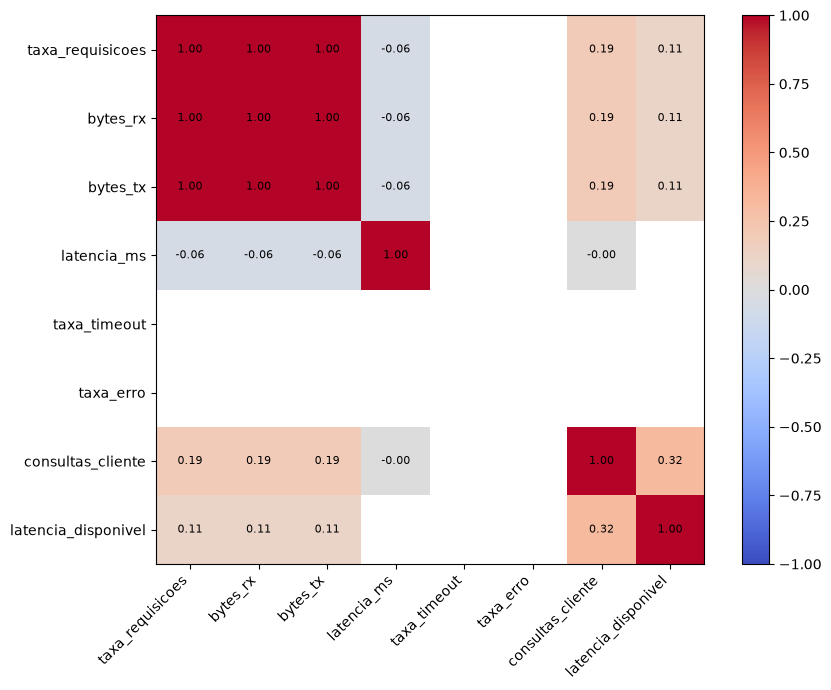

In [7]:
fig, ax = plt.subplots(
    figsize=(9, 7)
)

matriz = numericas.to_numpy()

imagem = ax.imshow(
    matriz,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(
    range(len(numericas.columns)),
    numericas.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(numericas.index)),
    numericas.index
)

for i in range(len(numericas.index)):
    for j in range(len(numericas.columns)):

        valor = matriz[i, j]

        if not np.isnan(valor):

            ax.text(
                j,
                i,
                f"{valor:.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

fig.colorbar(imagem, ax=ax)

plt.tight_layout()
plt.show()

In [8]:
COLUNAS_AVALIACAO = [
    "label",
    "fase",
    "nivel_carga",
    "condicao",
    "manutencao_legitima",
    "seed",
    "ensaio",
    "split",
    "janela_transicao",
    "consultas_cliente"
]

COLUNAS_ML = [
    "taxa_requisicoes",
    "latencia_ms",
    "latencia_disponivel"
]

In [9]:
resumo_ml = (
    dataset.groupby("condicao")[
        [
            "taxa_requisicoes",
            "latencia_ms",
            "latencia_disponivel"
        ]
    ]
    .agg([
        "mean",
        "std",
        "median",
        "min",
        "max"
    ])
)

display(
    resumo_ml.round(3)
)

taxa_requisicoes                          latencia_ms         \
                        mean    std median  min   max        mean    std   
condicao                                                                   
carga_alta            10.524  2.143   11.0  1.0  12.0       2.285  0.794   
carga_baixa            3.000  0.484    3.0  2.0   4.0       2.322  0.723   
carga_media            5.983  0.354    6.0  5.0   7.0       2.369  0.793   
manutencao             4.878  0.876    5.0  0.0   6.0       2.422  0.349   
normal                 1.022  0.408    1.0  0.0   2.0       2.376  0.737   
recuperacao            0.986  0.376    1.0  0.0   2.0       2.495  0.759   

                                 latencia_disponivel                        
            median    min    max                mean    std median min max  
condicao                                                                    
carga_alta   2.296  0.764  4.789               0.940  0.237    1.0   0   1  
carga_baixa  2.408  0.577  4.198               0.883  0.322    1.0   0   1  
carga_media  2.449  0.719  5.047               0.929  0.257    1.0   0   1  
manutencao   2.411  1.590  3.702               0.994  0.075    1.0   0   1  
normal       2.451  0.732  4.507               0.926  0.262    1.0   0   1  
recuperacao  2.612  0.822  8.425               0.924  0.266    1.0   0   1

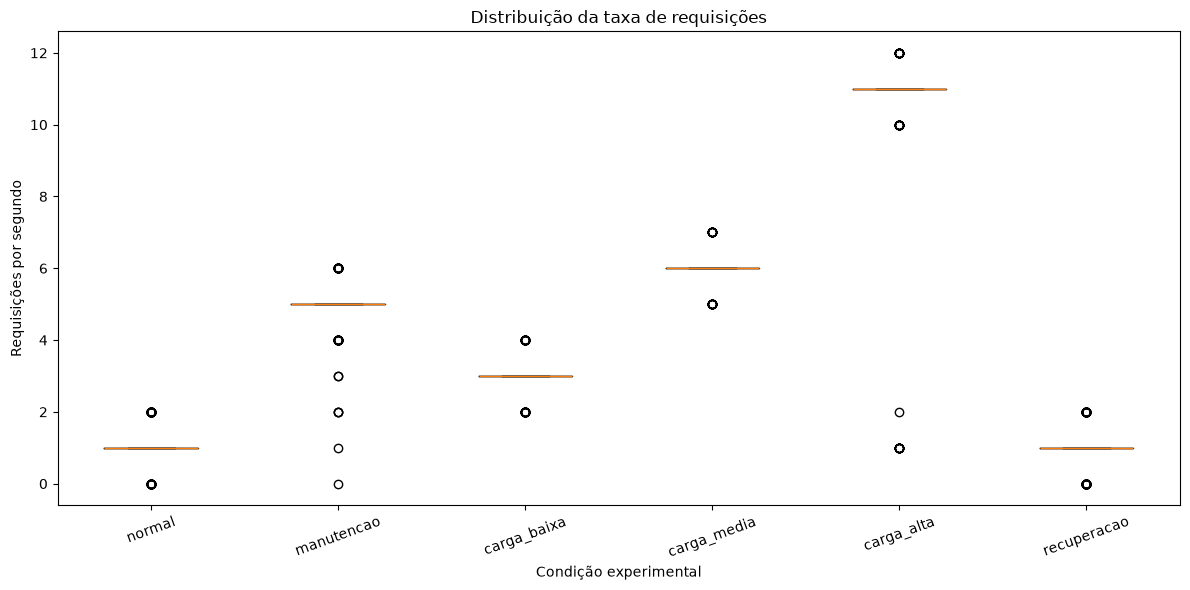

In [10]:
ordem = [
    "normal",
    "manutencao",
    "carga_baixa",
    "carga_media",
    "carga_alta",
    "recuperacao"
]

dados_boxplot = [
    dataset.loc[
        dataset["condicao"] == condicao,
        "taxa_requisicoes"
    ].values
    for condicao in ordem
]

fig, ax = plt.subplots(
    figsize=(12, 6)
)

ax.boxplot(
    dados_boxplot,
    tick_labels=ordem,
    showfliers=True
)

ax.set_title(
    "Distribuição da taxa de requisições"
)

ax.set_ylabel(
    "Requisições por segundo"
)

ax.set_xlabel(
    "Condição experimental"
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [11]:
display(
    pd.crosstab(
        dataset["condicao"],
        dataset["janela_transicao"]
    )
)

janela_transicao,0,1
condicao,,
carga_alta,228,24
carga_baixa,216,24
carga_media,216,24
manutencao,156,24
normal,492,48
recuperacao,684,24


In [12]:
print(
    "Total de janelas de transição:",
    dataset[
        "janela_transicao"
    ].sum()
)

print(
    "Percentual:",
    round(
        dataset[
            "janela_transicao"
        ].mean() * 100,
        2
    ),
    "%"
)

Total de janelas de transição: 168
Percentual: 7.78 %
